## Attention scale

셀프 어텐션에서 어텐션 점수는 쿼리와 키의 닷 프로덕트를 취하여 계산됩니다. 적절한 스케일링이 없으면 이러한 점수는 매우 커질 수 있으며(특히 임베딩 차원이 높을수록), 매우 가파른 소프트맥스 함수로 이어져 기울기 소실 또는 폭발을 일으켜 훈련을 어렵게 만들 수 있습니다.

### `sqrt(d_k)`로 스케일링하는 역할

일반적인 방법은 쿼리와 키의 닷 프로덕트를 키 벡터의 차원(`d_k`, 코드에서는 `emb_dim`)의 제곱근으로 나누는 것입니다. 이 스케일링 계수는 어텐션 점수의 분산을 정규화하여 소프트맥스 함수가 더 안정적인 영역에서 작동하도록 돕습니다. 이는 더 다양한 어텐션 가중치와 훈련 중 더 나은 기울기 흐름으로 이어집니다.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

def test_scale(X, use_scale=True):
    seq_len, d_model = X.shape

    torch.manual_seed(123)

    # Linear transformations for Query, Key, and Value
    Q = nn.Linear(d_model, d_model, bias=False)
    K = nn.Linear(d_model, d_model, bias=False)
    V = nn.Linear(d_model, d_model, bias=False)

    query, key, value = Q(X), K(X), V(X)

    # Calculate the scaling factor: sqrt(d_k) if use_scale is True, otherwise 1.0
    scale = d_model ** 0.5 if use_scale else 1.0 # use_scale이 False이면 scale 적용하지 않음

    # Calculate attention scores: (Query * Key_T) / scale
    attn_scores = query @ key.T / scale

    # Apply softmax to get attention weights
    attn_weights = F.softmax(attn_scores, dim=-1)

    return attn_weights, attn_scores

In [4]:
import pandas as pd
torch.manual_seed(123)

d_models = [16, 512] # embedding 크기 변화하면서 테스트 (d_k dimensions)
seq_len = 100

results = []

for d_model in d_models:
    X = torch.randn(seq_len, d_model)
    for scale_option in [False, True]: # use_scale True/False
        # Perform the attention calculation with the current embedding dimension and scaling option
        attn_weights, attn_scores = test_scale(X, use_scale=scale_option)

        # Collect statistics
        result_row = {
            'd_model': d_model,
            'scale': scale_option,
            'Scores_Mean': attn_scores.mean().item(),
            'Scores_Std': attn_scores.std().item(),
            'Scores_Max': attn_scores.max().item(),
            'Scores_Min': attn_scores.min().item(),
            'Weights_Mean': attn_weights.mean().item(),
            'Weights_Std': attn_weights.std().item(),
            'Weights_Max': attn_weights.max().item(),
            'Weights_Min': attn_weights.min().item()
        }
        results.append(result_row)

df_results = pd.DataFrame(results)
df_results.round(4)

,d_model,scale,Scores_Mean,Scores_Std,Scores_Max,Scores_Min,Weights_Mean,Weights_Std,Weights_Max,Weights_Min
0,16,False,0.0006,1.2447,6.0995,-6.0986,0.01,0.0172,0.5828,0.0000
1,16,True,0.0001,0.3112,1.5249,-1.5247,0.01,0.0032,0.0429,0.0018
2,512,False,-0.0160,7.5607,35.5236,-31.3046,0.01,0.0793,1.0000,0.0000
3,512,True,-0.0007,0.3341,1.5699,-1.3835,0.01,0.0034,0.0434,0.0024


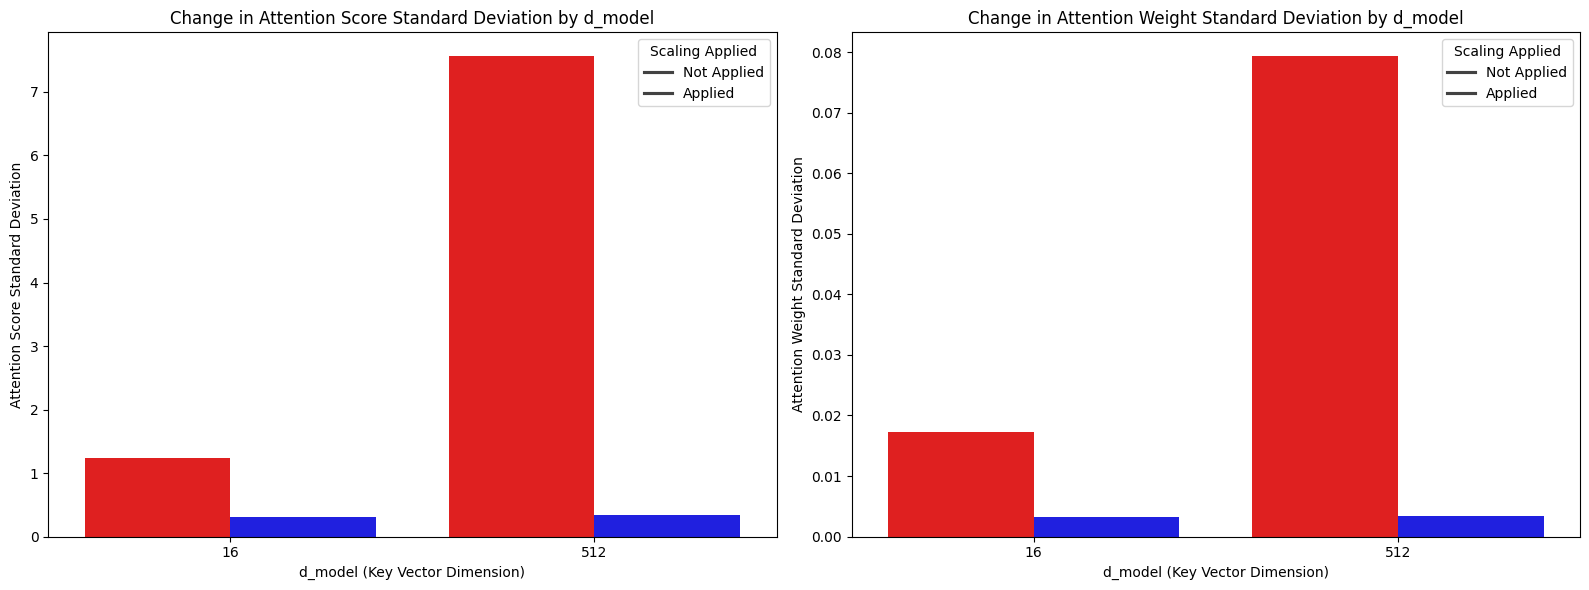

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Visualize standard deviation of attention scores
sns.barplot(x='d_model', y='Scores_Std', hue='scale', data=df_results, ax=axes[0], palette=['red', 'blue'])
axes[0].set_title('Change in Attention Score Standard Deviation by d_model')
axes[0].set_xlabel('d_model (Key Vector Dimension)')
axes[0].set_ylabel('Attention Score Standard Deviation')
axes[0].legend(title='Scaling Applied', labels=['Not Applied', 'Applied'])

# Visualize standard deviation of attention weights
sns.barplot(x='d_model', y='Weights_Std', hue='scale', data=df_results, ax=axes[1], palette=['red', 'blue'])
axes[1].set_title('Change in Attention Weight Standard Deviation by d_model')
axes[1].set_xlabel('d_model (Key Vector Dimension)')
axes[1].set_ylabel('Attention Weight Standard Deviation')
axes[1].legend(title='Scaling Applied', labels=['Not Applied', 'Applied'])

plt.tight_layout()
plt.show()

## 시각화 결과 설명

위 그래프는 `d_model` (키 벡터 차원, `d_k`)이 커짐에 따라 스케일링이 어텐션 스코어와 가중치에 미치는 영향을 시각적으로 보여줍니다.

### 1. 어텐션 스코어 표준편차 (`Scores_Std`) 변화
*   **스케일링 미적용 (빨간색 막대):** `d_model`이 `16`에서 `512`로 증가할 때 어텐션 스코어의 표준편차가 **급격히 증가**하는 것을 볼 수 있습니다. 이는 `d_model`이 커질수록 닷 프로덕트 값이 더욱 커져 소프트맥스 입력이 극단적인 값을 가지게 됨을 의미합니다.
*   **스케일링 적용 (파란색 막대):** `d_model`이 `16`에서 `512`로 증가하더라도 어텐션 스코어의 표준편차가 **매우 안정적**으로 유지됩니다. 이는 `sqrt(d_k)`로 나누어줌으로써 스코어의 스케일이 제어되고 있음을 명확히 보여줍니다.

### 2. 어텐션 가중치 표준편차 (`Weights_Std`) 변화
*   **스케일링 미적용 (빨간색 막대):** `d_model`이 `16`에서 `512`로 증가할 때 어텐션 가중치의 표준편차도 **증가**합니다. `d_model=512`의 경우, 표준편차가 커진다는 것은 어텐션 가중치 분포가 0과 1에 가까운 극단적인 값으로 집중되어 '과도한 확신'을 보이는 경향이 강해진다는 것을 나타냅니다.
*   **스케일링 적용 (파란색 막대):** 스케일링을 적용하면 `d_model` 값에 관계없이 어텐션 가중치의 표준편차가 **낮고 안정적**으로 유지됩니다. 이는 어텐션 가중치들이 0과 1 사이에 고르게 분포되어, 모델이 다양한 입력 토큰에 대해 더 균형 잡힌 주의를 기울일 수 있음을 의미합니다.

### 결론
이 시각화는 `d_k`가 커질수록 스케일링이 없을 때 어텐션 메커니즘이 얼마나 불안정해지는지, 그리고 `sqrt(d_k)` 스케일링이 이 불안정성을 효과적으로 완화하여 안정적이고 유의미한 어텐션 학습을 가능하게 하는 **필수적인 요소**임을 강력하게 뒷받침합니다.

## 스케일링 효과 분석

출력을 검토하여 `sqrt(d_k)`에 의한 스케일링의 중요한 역할을 관찰할 수 있습니다.

### 스케일링 없을 때 (`scale_option=False`):
*   **어텐션 점수:** `emb_dim` (`d_k`)이 증가할수록 어텐션 점수의 평균과 표준 편차가 크게 증가하는 경향이 있습니다. 최대값과 최소값 사이의 범위도 매우 커집니다. 이는 소프트맥스 함수의 입력이 매우 큰 양수 또는 매우 큰 음수 값이 되게 만듭니다.
*   **어텐션 가중치:** 소프트맥스 함수는 큰 숫자를 입력으로 받으면 매우 날카로워져 많은 어텐션 가중치가 0에 매우 가깝고 소수의 가중치가 1에 매우 가까워집니다. 이는 모델이 하나 또는 몇 개의 위치에만 너무 확신을 가지고 주의를 기울여 시퀀스의 다른 관련 부분을 무시할 가능성이 있습니다. 이는 작은 가중치에 대한 기울기 소실과 큰 가중치에 대한 기울기 폭발을 초래하여 효과적인 학습을 방해할 수 있습니다.

### 스케일링 있을 때 (`scale_option=True`):
*   **어텐션 점수:** `emb_dim`이 증가하더라도 어텐션 점수의 평균과 표준 편차는 훨씬 더 안정적이고 제어됩니다. 점수 범위도 상당히 작습니다.
*   **어텐션 가중치:** 결과적인 어텐션 가중치는 더 넓게 분포되고 다양합니다(더 작은 표준 편차와 덜 극단적인 최대/최소 값으로 표시됨). 이를 통해 모델은 여러 위치의 기여를 고려할 수 있으며, 이는 더 풍부한 표현과 더 안정적인 학습으로 이어집니다.